<a href="https://colab.research.google.com/github/shaikzayanahmed/DAV_LAB/blob/main/DAV_LAB_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LAB 05 Outliers

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

data={
    "Student":["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O"],
    "Study_hours":[2,3,4,5,4,6,5,3,4,5,6,4,5,30,3]
    }
df=pd.DataFrame(data)

print("Originl Dataframe")
print(df)

Originl Dataframe
   Student  Study_hours
0        A            2
1        B            3
2        C            4
3        D            5
4        E            4
5        F            6
6        G            5
7        H            3
8        I            4
9        J            5
10       K            6
11       L            4
12       M            5
13       N           30
14       O            3


In [ ]:
df["Study_hours"].describe()

,Study_hours
count,15.000000
mean,5.933333
std,6.755597
min,2.000000
25%,3.500000
50%,4.000000
75%,5.000000
max,30.000000


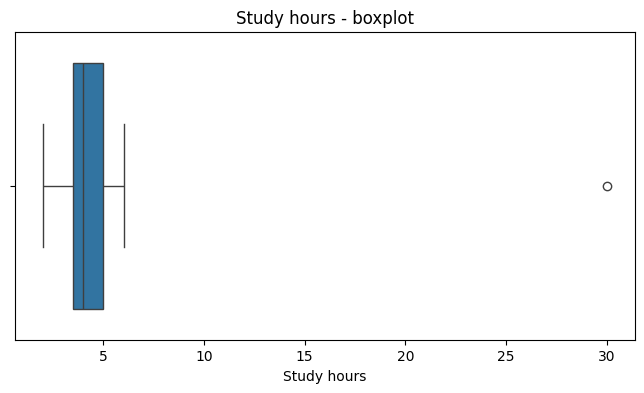

In [ ]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["Study_hours"])
plt.title("Study hours - boxplot")
plt.xlabel("Study hours")
plt.show()

IQR method (Inter Quantier Range) Method

step 1-Find Q1 and Q3

then IQR=Q3-Q1 is the formula

In [ ]:
Q1=df["Study_hours"].quantile(0.25)
Q3=df["Study_hours"].quantile(0.75)

print("Q1",Q1)
print("Q3",Q3)

Q1 3.5
Q3 5.0


In [ ]:
IQR=Q3-Q1
print("IQR:",IQR)

IQR: 1.5


In [ ]:
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR

print("lower bound:",lower_bound)
print("upper bound:",upper_bound)

lower bound: 1.25
upper bound: 7.25


In [ ]:
outliers_iqr=df[
    (df["Study_hours"]<lower_bound) | (df["Study_hours"]>upper_bound)
]

print("IQR Outliers")
print(outliers_iqr)


IQR Outliers
   Student  Study_hours
13       N           30


In [ ]:
outliers_iqr=df[
    (df["Study_hours"]>=lower_bound) & (df["Study_hours"]<=upper_bound)
]

print("IQR Outliers")
print(outliers_iqr)

IQR Outliers
   Student  Study_hours
0        A            2
1        B            3
2        C            4
3        D            5
4        E            4
5        F            6
6        G            5
7        H            3
8        I            4
9        J            5
10       K            6
11       L            4
12       M            5
14       O            3


In [ ]:
df["z_score"]=zscore(df["Study_hours"])
print("Dataset with Z scores")
print(df)

Dataset with Z scores
   Student  Study_hours   z_score
0        A            2 -0.602669
1        B            3 -0.449448
2        C            4 -0.296227
3        D            5 -0.143006
4        E            4 -0.296227
5        F            6  0.010215
6        G            5 -0.143006
7        H            3 -0.449448
8        I            4 -0.296227
9        J            5 -0.143006
10       K            6  0.010215
11       L            4 -0.296227
12       M            5 -0.143006
13       N           30  3.687515
14       O            3 -0.449448


In [ ]:
z_outliers=df[
    (df["z_score"]>3) | (df["z_score"]<-3)
]

print("Z score outliers")
print(z_outliers)

Z score outliers
   Student  Study_hours   z_score
13       N           30  3.687515


In [ ]:
df_without_outliers=df[
    (df["Study_hours"]>=lower_bound) & (df["Study_hours"]<=upper_bound)
]

display(df_without_outliers)

,Student,Study_hours,z_score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006
